[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/03-math/01_arithmetic.ipynb)

*Math for Data Science & ML · Notebook 1 of 10*

# Numbers & Arithmetic

The starting point: kinds of numbers, fractions, percentages, powers, roots, primes, rounding and the Σ notation every ML formula uses.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Everything in machine learning eventually reduces to these operations, done millions of times.

**What interviewers really test here:** Rounding errors, logs and exponents as used in loss functions.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Kinds of numbers *(Basics)*
- [ ] 2. The four operations and their order *(Basics)*
- [ ] 3. Fractions, decimals and percentages *(Basics)*
- [ ] 4. Negative numbers without fear *(Basics)*
- [ ] 5. GCD, LCM and primes by hand *(Basics)*
- [ ] 6. Powers and roots *(Core)*
- [ ] 7. The three kinds of percent problem *(Core)*
- [ ] 8. Exponent rules in action *(Core)*
- [ ] 9. Sigma notation, factorials and the language of formulas *(Advanced)*
- [ ] 10. Reading the formulas you'll meet in ML *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Which math does data science and machine learning need?

You do **not** need a math degree. You need five areas, and this course teaches them in this order because each one is built from the ones before it:



| \# | Area | What it gives you in ML | Topics here |
| --- | --- | --- | --- |
| 1 | **Foundations**: arithmetic, algebra, functions | reading and rearranging every formula; understanding a model as a function from inputs to outputs | 1 – 3 |
| 2 | **Linear algebra**: vectors, matrices, eigenvectors | data is stored as vectors and matrices; a neural network layer is a matrix multiply; PCA and embeddings come from eigenvectors | 4 – 6 |
| 3 | **Calculus**: derivatives, integrals, gradients | training = adjusting weights to make the error smaller, using derivatives (gradient descent, backpropagation) | 7 – 8 |
| 4 | **Probability** | reasoning under uncertainty; Naive Bayes; predictions as probabilities | 9 |
| 5 | **Distributions & information** | the normal curve, likelihood, and the loss functions (cross-entropy, log-loss) models minimise | 10 |



Descriptive statistics (mean, median, standard deviation, correlation, regression) is in the [Statistics topic of the Data Science course](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/t/statistics).



**How to study:** one lesson a day is enough. Read the plain-words explanation, look at the picture, then work one practice question with pen and paper *before* opening the answer.

### Number systems

| Set | Symbol | Contains |
| --- | --- | --- |
| Natural numbers | ℕ | 1, 2, 3, … (sometimes 0) |
| Integers | ℤ | whole numbers and their negatives |
| Rational numbers | ℚ | p/q with p, q integers, q ≠ 0; decimals that end or repeat |
| Irrational numbers | — | decimals that never end or repeat: √2, π, e |
| Real numbers | ℝ | rational + irrational: the whole number line |



ℕ ⊂ ℤ ⊂ ℚ ⊂ ℝ. A **prime** is a natural number greater than 1 whose only divisors are 1 and itself; every natural number above 1 is a unique product of primes (the Fundamental Theorem of Arithmetic).

### Operations, properties and order

- **Commutative**: a + b = b + a, a·b = b·a (not for − or ÷).
- **Associative**: (a + b) + c = a + (b + c); same for ×.
- **Distributive**: a(b + c) = ab + ac — the rule behind "expanding brackets".
- **Identity**: a + 0 = a, a·1 = a. **Inverse**: a + (−a) = 0, a·(1/a) = 1.
- Division by zero is undefined.
- Order of operations: brackets, powers/roots, × ÷ left to right, + − left to right.

### Fractions, ratios and percentages

- a/b = (a·k)/(b·k) for any k ≠ 0 — so you can simplify by the GCD or scale to a common denominator (the LCM of the bottoms).
- a/b + c/d = (ad + cb)/bd; a/b × c/d = ac/bd; a/b ÷ c/d = a/b × d/c.
- Percent = part / whole × 100. Percent change = (new − old) / old × 100. A 50% rise followed by a 50% fall is a 25% loss overall.
- A ratio a : b splits a quantity into a + b equal parts.

### Exponents, roots, logs preview and notation

| Rule | Formula |
| --- | --- |
| Product | xᵃ·xᵇ = xᵃ⁺ᵇ |
| Quotient | xᵃ / xᵇ = xᵃ⁻ᵇ |
| Power | (xᵃ)ᵇ = xᵃᵇ |
| Zero / negative | x⁰ = 1, x⁻ⁿ = 1/xⁿ |
| Fractional | x^(p/q) = (q√x)ᵖ |



**Scientific notation** writes x = a × 10ⁿ with 1 ≤ a &lt; 10; n = ⌊log₁₀ x⌋. **Significant figures** count digits from the first non-zero digit.



**Σ** means sum, **Π** means product, n! = 1·2·…·n. Useful closed forms: Σk = n(n+1)/2, Σk² = n(n+1)(2n+1)/6.

---
# Part 2: Lessons, step by step

## Lesson 1: Kinds of numbers

*Level: Basics*

Every number you will meet belongs to a family. Each family is bigger than the one before:



| Family | Examples | Used for |
| --- | --- | --- |
| **Natural** ℕ | 1, 2, 3, … | counting things |
| **Integers** ℤ | …, −2, −1, 0, 1, 2, … | gains and losses, floors above / below ground |
| **Rational** ℚ | ½, −3/4, 0.25 | parts of a whole — anything written as a fraction |
| **Real** ℝ | √2, π, 0.333… | every point on the number line, including ones no fraction reaches |



Picture a **number line**: zero in the middle, positives to the right, negatives to the left. The distance of a number from zero is its **absolute value**: |−3| = 3. The distance between a and b is |a − b|.



In Python, whole numbers are `int` and numbers with a decimal point are `float`. ML models work almost entirely with real numbers stored as floats.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

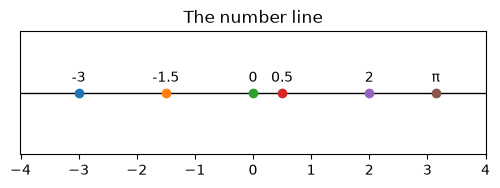

In [2]:
def number_line():
    points = [-3, -1.5, 0, 0.5, 2, math.pi]
    fig, ax = plt.subplots(figsize=(6, 1.6))
    ax.axhline(0, color="black", linewidth=1)
    for p in points:
        ax.plot(p, 0, "o")
        ax.annotate(f"{p:g}" if p != math.pi else "π", (p, 0), xytext=(0, 8), textcoords="offset points", ha="center")
    ax.set_yticks([])
    ax.set_xlim(-4, 4)
    ax.set_title("The number line")


number_line()

**✏️ Your turn:** you now have what you need for [Q15](#q15), [Q12](#q12). Try one now, or carry on and do them in Part 3.

## Lesson 2: The four operations and their order

*Level: Basics*

Addition, subtraction, multiplication and division are the building blocks. When an expression mixes them, follow **BODMAS** (also called PEMDAS):




1. **B**rackets first
2. **O**rders — powers and roots
3. **D**ivision and **M**ultiplication, left to right
4. **A**ddition and **S**ubtraction, left to right



Example: 2 + 3 × 4² = 2 + 3 × 16 = 2 + 48 = 50, not 400.



Division of whole numbers gives a **quotient** and a **remainder**: 17 ÷ 5 = 3 remainder 2, because 5 × 3 + 2 = 17. Python: `17 // 5` and `17 % 5`.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [3]:
def order_of_operations():
    step1 = 4 ** 2
    step2 = 3 * step1
    answer = 2 + step2
    python_says = 2 + 3 * 4 ** 2
    quotient = 17 // 5
    remainder = 17 % 5
    check = 5 * quotient + remainder


order_of_operations()

**✏️ Your turn:** you now have what you need for [Q10](#q10), [Q1](#q1), [Q2](#q2), [Q7](#q7), [Q16](#q16). Try one now, or carry on and do them in Part 3.

## Lesson 3: Fractions, decimals and percentages

*Level: Basics*

A **fraction** a/b means "split into b equal parts, take a of them". The same amount can be written three ways:



| Fraction | Decimal | Percent |
| --- | --- | --- |
| 1/2 | 0.5 | 50% |
| 3/4 | 0.75 | 75% |
| 1/3 | 0.333… | 33.3% |




- **Simplify**: divide top and bottom by their greatest common divisor — 12/18 = 2/3.
- **Add**: get a common bottom first — 1/2 + 1/3 = 3/6 + 2/6 = 5/6.
- **Percent** means "per hundred". Percent change = (new − old) / old × 100.
- **Ratio** 2 : 3 means "2 parts to 3 parts" — 5 parts in all.



In ML, accuracy, probabilities and learning rates are all fractions written as decimals.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

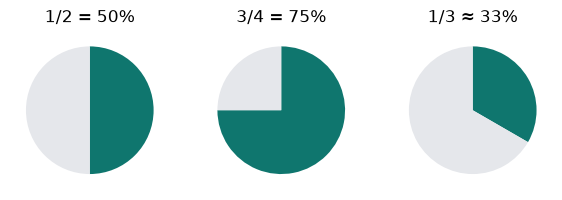

In [4]:
def fractions_demo():
    parts = [1, 2, 3, 4]
    fig, axes = plt.subplots(1, 3, figsize=(7, 2.4))
    for ax, (num, den, label) in zip(axes, [(1, 2, "1/2 = 50%"), (3, 4, "3/4 = 75%"), (1, 3, "1/3 ≈ 33%")]):
        ax.pie([num, den - num], colors=["#0f766e", "#e5e7eb"], startangle=90, counterclock=False)
        ax.set_title(label)


fractions_demo()

**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q4](#q4), [Q5](#q5), [Q6](#q6), [Q11](#q11). Try one now, or carry on and do them in Part 3.

## Lesson 4: Negative numbers without fear

*Level: Basics*

Think of a number line. **Adding** moves right, and **subtracting** moves left.



| Calculation | Think of it as | Answer |
| --- | --- | --- |
| −3 + 5 | start at −3, move 5 right | 2 |
| 2 − 6 | start at 2, move 6 left | −4 |
| −4 − 3 | start at −4, move 3 further left | −7 |
| 5 − (−2) | taking away a debt is like gaining | 7 |



#### Multiplying and dividing: count the minus signs



| Signs | Result | Example |
| --- | --- | --- |
| Same | positive | −2 × −4 = 8 |
| Different | negative | −2 × 4 = −8 |



**Why is −2 × −4 positive?** Follow the pattern: −2 × 2 = −4, −2 × 1 = −2, −2 × 0 = 0. Each step adds 2. Continue: −2 × −1 = 2, −2 × −2 = 4.



#### A common slip



−3² means −(3²) = **−9**, because powers come before the minus. (−3)² = **9**. Python agrees: `-3**2` gives −9.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [5]:
def negatives():
    moves = [-3 + 5, 2 - 6, -4 - 3, 5 - (-2)]
    pattern = [-2 * k for k in [2, 1, 0, -1, -2]]
    power_first = -3 ** 2
    bracket_first = (-3) ** 2


negatives()

**✏️ Your turn:** you now have what you need for [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 5: GCD, LCM and primes by hand

*Level: Basics*

#### Greatest common divisor, by Euclid's method



GCD of 48 and 18. Keep dividing and use the remainder:



```python
48 = 2 × 18 + 12
18 = 1 × 12 + 6
12 = 2 × 6  + 0      remainder 0, so the answer is 6
```



Use it to simplify: 48/18 = 8/3, dividing both by 6.



#### Least common multiple



LCM × GCD = a × b, so LCM(48, 18) = 48 × 18 / 6 = **144**. You need this as the common bottom when adding fractions.



#### Prime factors



Keep dividing by the smallest prime that fits:



```python
60 → 2 × 30 → 2 × 2 × 15 → 2 × 2 × 3 × 5
```



To test if a number is prime, you only need to try divisors up to its square root. If 97 had a factor above √97 ≈ 9.8, it would also have one below it. Trying 2, 3, 5 and 7 finds none, so 97 is prime.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [6]:
def euclid_steps():
    a, b = 48, 18
    steps = []
    while b:
        steps.append((a, b, a % b))
        a, b = b, a % b
    gcd = a
    lcm = 48 * 18 // gcd
    simplified = (48 // gcd, 18 // gcd)


euclid_steps()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q3](#q3), [Q7](#q7), [Q16](#q16). Try one now, or carry on and do them in Part 3.

## Lesson 6: Powers and roots

*Level: Core*

A **power** is repeated multiplication: 2⁴ = 2 × 2 × 2 × 2 = 16. The small number is the **exponent**.



| Rule | Example |
| --- | --- |
| xᵃ · xᵇ = xᵃ⁺ᵇ | 2³ · 2² = 2⁵ = 32 |
| (xᵃ)ᵇ = xᵃᵇ | (2³)² = 2⁶ = 64 |
| x⁰ = 1 | 7⁰ = 1 |
| x⁻ⁿ = 1 / xⁿ | 2⁻³ = 1/8 |
| x^(1/n) = ⁿ√x | 8^(1/3) = 2 |



A **square root** undoes squaring: √25 = 5 because 5² = 25. Very large and very small numbers are written in **scientific notation**: 45 000 = 4.5 × 10⁴, 0.00321 = 3.21 × 10⁻³ (Python prints `4.5e4`).

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

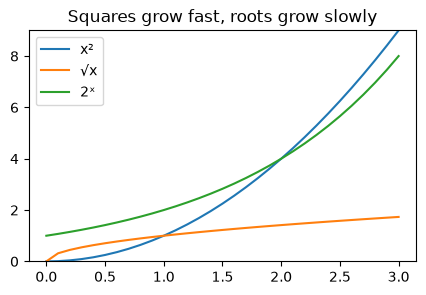

In [7]:
def powers_graph():
    xs = [x / 10 for x in range(0, 31)]
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(xs, [x ** 2 for x in xs], label="x²")
    ax.plot(xs, [x ** 0.5 for x in xs], label="√x")
    ax.plot(xs, [2 ** x for x in xs], label="2ˣ")
    ax.set_ylim(0, 9)
    ax.legend()
    ax.set_title("Squares grow fast, roots grow slowly")


powers_graph()

**✏️ Your turn:** you now have what you need for [Q8](#q8), [Q17](#q17), [Q18](#q18), [Q9](#q9), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 7: The three kinds of percent problem

*Level: Core*

| Question | Method | Answer |
| --- | --- | --- |
| What is 20% of 250? | 0.20 × 250 | 50 |
| 30 is what percent of 120? | 30 / 120 × 100 | 25% |
| After 20% off, a price is 400. What was it? | 400 / 0.80 | 500 |



#### The third one catches people



The wrong way: 400 + 20% of 400 = 480. The discount was 20% of the **original**, not of 400. So 0.80 × original = 400.



#### Percentages don't simply add



₹100 rises 50% to ₹150, then falls 50% to **₹75**. The second percent is taken from a bigger number. Multiply instead: 100 × 1.5 × 0.5.



#### Percent vs percentage points



An accuracy rising from 80% to 88% is up **8 percentage points**, or **10 percent** (8 / 80). Say which you mean.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [8]:
def percent_steps():
    share = 0.20 * 250
    what_percent = 30 / 120 * 100
    original = 400 / 0.80
    up_then_down = 100 * 1.5 * 0.5
    points = 88 - 80
    percent_rise = (88 - 80) / 80 * 100


percent_steps()

**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q5](#q5), [Q11](#q11). Try one now, or carry on and do them in Part 3.

## Lesson 8: Exponent rules in action

*Level: Core*

Each rule follows from "a power means repeated multiplying".



| Simplify | Why | Answer |
| --- | --- | --- |
| 2³ × 2⁴ | (2·2·2)(2·2·2·2): 7 twos | 2⁷ = 128 |
| x⁵ / x² | two x's cancel | x³ |
| (x²)³ | x²·x²·x² | x⁶ |
| 5⁰ | 5³ / 5³ = 1 | 1 |
| 2⁻³ | one over 2³ | 1/8 |
| 8^(2/3) | cube root of 8 is 2, then square it | 4 |



#### Mistakes to avoid



- 2³ × 3² can't be combined, as the bases differ.
- (a + b)² isn't a² + b². Try a = b = 1: it gives 4, not 2.



#### Scientific notation



Multiply the front numbers and add the powers: (3 × 10⁴) × (2 × 10⁻²) = 6 × 10² = 600. This is how you estimate quickly, and why logs turn multiplying into adding.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [9]:
def exponent_checks():
    product_rule = (2 ** 3 * 2 ** 4, 2 ** 7)
    power_rule = ((3 ** 2) ** 3, 3 ** 6)
    zero_power = 5 ** 0
    negative = 2 ** -3
    fractional = round(8 ** (2 / 3), 6)
    not_equal = ((1 + 1) ** 2, 1 ** 2 + 1 ** 2)
    scientific = 3e4 * 2e-2


exponent_checks()

**✏️ Your turn:** you now have what you need for [Q8](#q8), [Q17](#q17), [Q9](#q9), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 9: Sigma notation, factorials and the language of formulas

*Level: Advanced*

ML papers are full of **Σ** (capital sigma). It just means "add up":



```python
  n
  Σ  k²   =  1² + 2² + … + n²          total = 0
 k=1                                    for k in range(1, n + 1):
                                            total += k ** 2
```



Read it as a loop: k starts at the bottom number, stops at the top, and you add the expression each time. **Π** (capital pi) is the same with multiplication. The **factorial** n! = n × (n−1) × … × 1 counts the ways to arrange n things.



The mean of n numbers is written x̄ = (1/n) Σ xᵢ — that is all "average" means. Once you can read Σ, most formulas in data science become loops you already understand.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [10]:
def sigma_demo():
    n = 5
    total = 0
    for k in range(1, n + 1):
        total += k ** 2
    formula = n * (n + 1) * (2 * n + 1) // 6
    product = 1
    for k in range(1, n + 1):
        product *= k


sigma_demo()

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q20](#q20), [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 10: Reading the formulas you'll meet in ML

*Level: Advanced*

Σ is just a loop. Here's how to expand any formula: write it out for i = 1, 2, 3.



| Formula | Written out | With numbers |
| --- | --- | --- |
| Σᵢ₌₁³ 2i | 2·1 + 2·2 + 2·3 | 12 |
| x̄ = (1/n) Σ xᵢ | (x₁ + x₂ + x₃) / 3 | x = 2, 4, 9 gives 5 |
| MSE = (1/n) Σ (yᵢ − ŷᵢ)² | average of squared errors | errors 1, −2, 3 give 14/3 = 4.67 |
| w·x = Σ wᵢxᵢ | w₁x₁ + w₂x₂ | (2, 3)·(4, 5) = 23 |



#### Rules that make Σ easy



- A constant comes out: Σ 3xᵢ = 3 Σ xᵢ.
- Sums split: Σ (xᵢ + yᵢ) = Σ xᵢ + Σ yᵢ.
- But products don't: Σ xᵢyᵢ isn't (Σ xᵢ)(Σ yᵢ).



#### Symbols to recognise



|   |   |   |   |
| --- | --- | --- | --- |
| x̄ | the mean of x | ŷ | a prediction |
| xᵢ | the i-th item | θ, w | model parameters |
| Π | multiply all | argmax | the input that gives the largest output |
| ∈ | "is in" | ≈ | about equal |

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [11]:
def formulas_as_code():
    x = [2, 4, 9]
    mean = sum(x) / len(x)
    errors = [1, -2, 3]
    mse = sum(e ** 2 for e in errors) / len(errors)
    w, features = [2, 3], [4, 5]
    weighted_sum = sum(a * b for a, b in zip(w, features))
    constant_out = (sum(3 * v for v in x), 3 * sum(x))


formulas_as_code()

**✏️ Your turn:** you now have what you need for [Q20](#q20), [Q13](#q13), [Q14](#q14). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [12]:
from fractions import Fraction


<a id="q1"></a>
### Q1. Greatest Common Divisor

🟢 Warm-up · *Euclid's algorithm*

Return the largest whole number that divides both a and b exactly.

**Examples**

- `a = 12, b = 18` → `6`
- `a = 17, b = 5` → `1`
- `a = 100, b = 75` → `25`

In [ ]:
def gcd(a, b):
    """
    Return the largest whole number that divides both a and b exactly.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(gcd, [
    ((12, 18), 6),
    ((17, 5), 1),
    ((100, 75), 25),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Euclid: replace (a, b) with (b, a mod b) until b is 0 — the last non-zero value is the answer.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`math.gcd(a, b)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Euclid: replace (a, b) with (b, a mod b) until b is 0 — the last non-zero value is the answer.

```python
def gcd(a, b):
    while b != 0:
        remainder = a % b
        a = b
        b = remainder
    return a
```

**Cost:** O(log min(a, b)) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `math.gcd(a, b)`.

```python
def gcd(a, b):
    return math.gcd(a, b)
```

**Cost:** O(log min(a, b)) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Euclid: replace (a, b) with (b, a mod b) until b is 0 — the last non-zero value is the answer. That costs O(log min(a, b)) time and O(1) space."

"I can do better: `math.gcd(a, b)`. That's O(log min(a, b)) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/arithmetic/greatest-common-divisor)

<a id="q2"></a>
### Q2. Least Common Multiple

🟢 Warm-up · *LCM = a·b / gcd*

Return the smallest positive number that both a and b divide into.

**Examples**

- `a = 4, b = 6` → `12`
- `a = 3, b = 5` → `15`
- `a = 8, b = 12` → `24`

In [ ]:
def lcm(a, b):
    """
    Return the smallest positive number that both a and b divide into.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(lcm, [
    ((4, 6), 12),
    ((3, 5), 15),
    ((8, 12), 24),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

List multiples of the larger number until one is also a multiple of the smaller.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`a * b // gcd(a, b)` (or `math.lcm`).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** List multiples of the larger number until one is also a multiple of the smaller.

```python
def lcm(a, b):
    big, small = max(a, b), min(a, b)
    multiple = big
    while multiple % small != 0:
        multiple += big
    return multiple
```

**Cost:** O(min(a, b)) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `a * b // gcd(a, b)` (or `math.lcm`).

```python
def lcm(a, b):
    return a * b // math.gcd(a, b)
```

**Cost:** O(log min(a, b)) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: List multiples of the larger number until one is also a multiple of the smaller. That costs O(min(a, b)) time and O(1) space."

"I can do better: `a * b // gcd(a, b)` (or `math.lcm`). That's O(log min(a, b)) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/arithmetic/least-common-multiple)

<a id="q3"></a>
### Q3. Simplify a Fraction

🟢 Warm-up · *Lowest terms*

Return the fraction num/den in lowest terms as (numerator, denominator).

**Examples**

- `num = 12, den = 18` → `(2, 3)`
- `num = 5, den = 10` → `(1, 2)`
- `num = 7, den = 3` → `(7, 3)`

In [ ]:
def simplify(num, den):
    """
    Return the fraction num/den in lowest terms as (numerator, denominator).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(simplify, [
    ((12, 18), (2, 3)),
    ((5, 10), (1, 2)),
    ((7, 3), (7, 3)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Try every divisor from the smaller number down; the first that divides both is the GCD.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Divide both by `math.gcd` — or let `Fraction` do it.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Try every divisor from the smaller number down; the first that divides both is the GCD.

```python
def simplify(num, den):
    for d in range(min(num, den), 0, -1):
        if num % d == 0 and den % d == 0:
            return (num // d, den // d)
```

**Cost:** O(min(n, d)) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Divide both by `math.gcd` — or let `Fraction` do it.

```python
def simplify(num, den):
    f = Fraction(num, den)
    return (f.numerator, f.denominator)
```

**Cost:** O(log n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Try every divisor from the smaller number down; the first that divides both is the GCD. That costs O(min(n, d)) time and O(1) space."

"I can do better: Divide both by `math.gcd` — or let `Fraction` do it. That's O(log n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/arithmetic/simplify-a-fraction)

<a id="q4"></a>
### Q4. Add Two Fractions

🟢 Warm-up · *Common denominator*

Return a/b + c/d in lowest terms as (numerator, denominator).

**Examples**

- `a = 1, b = 2, c = 1, d = 3` → `(5, 6)`
- `a = 3, b = 4, c = 1, d = 6` → `(11, 12)`
- `a = 1, b = 4, c = 3, d = 4` → `(1, 1)`

In [ ]:
def add_fractions(a, b, c, d):
    """
    Return a/b + c/d in lowest terms as (numerator, denominator).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(add_fractions, [
    ((1, 2, 1, 3), (5, 6)),
    ((3, 4, 1, 6), (11, 12)),
    ((1, 4, 3, 4), (1, 1)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Common denominator b·d, numerator a·d + c·b, then simplify with Euclid.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Fraction(a, b) + Fraction(c, d)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Common denominator b·d, numerator a·d + c·b, then simplify with Euclid.

```python
def add_fractions(a, b, c, d):
    num = a * d + c * b
    den = b * d
    x, y = num, den
    while y:
        x, y = y, x % y
    return (num // x, den // x)
```

**Cost:** O(log bd) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `Fraction(a, b) + Fraction(c, d)`.

```python
def add_fractions(a, b, c, d):
    f = Fraction(a, b) + Fraction(c, d)
    return (f.numerator, f.denominator)
```

**Cost:** O(log bd) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Common denominator b·d, numerator a·d + c·b, then simplify with Euclid. That costs O(log bd) time and O(1) space."

"I can do better: `Fraction(a, b) + Fraction(c, d)`. That's O(log bd) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/arithmetic/add-two-fractions)

<a id="q5"></a>
### Q5. Fraction to Decimal and Percent

🟢 Warm-up · *Three ways to write a part*

Return (decimal, percent) for num/den, the decimal rounded to 4 places and the percent to 2.

**Examples**

- `num = 3, den = 4` → `(0.75, 75.0)`
- `num = 1, den = 3` → `(0.3333, 33.33)`
- `num = 5, den = 2` → `(2.5, 250.0)`

In [ ]:
def to_decimal(num, den):
    """
    Return (decimal, percent) for num/den, the decimal rounded to 4 places and
    the percent to 2.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(to_decimal, [
    ((3, 4), (0.75, 75.0)),
    ((1, 3), (0.3333, 33.33)),
    ((5, 2), (2.5, 250.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Long division digit by digit, then shift the point two places for percent.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`num / den` and multiply by 100.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Long division digit by digit, then shift the point two places for percent.

```python
def to_decimal(num, den):
    whole = num // den
    rest = num % den
    digits = []
    for _ in range(6):
        rest *= 10
        digits.append(rest // den)
        rest = rest % den
    value = whole + sum(dg / 10 ** (i + 1) for i, dg in enumerate(digits))
    return (round(value, 4), round(value * 100, 2))
```

**Cost:** O(digits) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `num / den` and multiply by 100.

```python
def to_decimal(num, den):
    value = num / den
    return (round(value, 4), round(value * 100, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Long division digit by digit, then shift the point two places for percent. That costs O(digits) time and O(1) space."

"I can do better: `num / den` and multiply by 100. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/arithmetic/fraction-to-decimal-and-percent)

<a id="q6"></a>
### Q6. Percent Change

🟢 Warm-up · *(new − old) / old*

Return the percentage change from old to new, rounded to 2 decimals (negative means a decrease).

**Examples**

- `old = 50, new = 60` → `20.0`
- `old = 80, new = 60` → `-25.0`
- `old = 200, new = 200` → `0.0`

In [ ]:
def percent_change(old, new):
    """
    Return the percentage change from old to new, rounded to 2 decimals
    (negative means a decrease).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(percent_change, [
    ((50, 60), 20.0),
    ((80, 60), -25.0),
    ((200, 200), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Find the difference, then ask: what share of the old value is it?

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

For many values at once: `(new - old) / old * 100` on NumPy arrays.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Find the difference, then ask: what share of the old value is it?

```python
def percent_change(old, new):
    difference = new - old
    share = difference / old
    return round(share * 100, 2)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** For many values at once: `(new - old) / old * 100` on NumPy arrays.

```python
def percent_change(old, new):
    return round(float((np.array(new) - old) / old * 100), 2)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Find the difference, then ask: what share of the old value is it? That costs O(1) time and O(1) space."

"I can do better: For many values at once: `(new - old) / old * 100` on NumPy arrays. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/arithmetic/percent-change)

<a id="q7"></a>
### Q7. Is It Prime?

🟢 Warm-up · *Trial division to √n*

Return True if n is prime (exactly two divisors: 1 and itself).

**Examples**

- `n = 2` → `True`
- `n = 15` → `False`
- `n = 97` → `True`

In [ ]:
def is_prime(n):
    """
    Return True if n is prime (exactly two divisors: 1 and itself).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(is_prime, [
    ((2,), True),
    ((15,), False),
    ((97,), True),
    ((1,), False),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Try every divisor from 2 to n − 1.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Only test up to √n: if n = a·b, one of a, b is at most √n.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Try every divisor from 2 to n − 1.

```python
def is_prime(n):
    if n < 2:
        return False
    for d in range(2, n):
        if n % d == 0:
            return False
    return True
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Only test up to √n: if n = a·b, one of a, b is at most √n.

```python
def is_prime(n):
    if n < 2:
        return False
    for d in range(2, math.isqrt(n) + 1):
        if n % d == 0:
            return False
    return True
```

**Cost:** O(√n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Try every divisor from 2 to n − 1. That costs O(n) time and O(1) space."

"I can do better: Only test up to √n: if n = a·b, one of a, b is at most √n. That's O(√n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/arithmetic/is-it-prime)

<a id="q8"></a>
### Q8. Power by Repeated Multiplication

🟢 Warm-up · *Exponents*

Return base \*\* exp for a whole number exp ≥ 0, without using \*\*.

**Examples**

- `base = 2, exp = 10` → `1024`
- `base = 5, exp = 0` → `1`
- `base = 3, exp = 4` → `81`

In [ ]:
def power(base, exp):
    """
    Return base ** exp for a whole number exp ≥ 0, without using **.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(power, [
    ((2, 10), 1024),
    ((5, 0), 1),
    ((3, 4), 81),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Start at 1 and multiply by the base exp times.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Squaring: x⁸ = ((x²)²)², so only O(log exp) multiplications (what `pow` does).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Start at 1 and multiply by the base exp times.

```python
def power(base, exp):
    result = 1
    for _ in range(exp):
        result *= base
    return result
```

**Cost:** O(exp) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Squaring: x⁸ = ((x²)²)², so only O(log exp) multiplications (what `pow` does).

```python
def power(base, exp):
    result = 1
    while exp > 0:
        if exp % 2 == 1:
            result *= base
        base *= base
        exp //= 2
    return result
```

**Cost:** O(log exp) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Start at 1 and multiply by the base exp times. That costs O(exp) time and O(1) space."

"I can do better: Squaring: x⁸ = ((x²)²)², so only O(log exp) multiplications (what `pow` does). That's O(log exp) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/arithmetic/power-by-repeated-multiplication)

<a id="q9"></a>
### Q9. Scientific Notation

🟢 Warm-up · *a × 10ⁿ with 1 ≤ a &lt; 10*

Return (mantissa rounded to 3 decimals, exponent) for a positive number, e.g. 45000 → (4.5, 4).

**Examples**

- `x = 45000` → `(4.5, 4)`
- `x = 0.00321` → `(3.21, -3)`
- `x = 7` → `(7.0, 0)`

In [ ]:
def sci(x):
    """
    Return (mantissa rounded to 3 decimals, exponent) for a positive number,
    e.g. 45000 → (4.5, 4).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sci, [
    ((45000,), (4.5, 4)),
    ((0.00321,), (3.21, -3)),
    ((7,), (7.0, 0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Divide (or multiply) by 10 until the number is between 1 and 10, counting the steps.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

The exponent is `floor(log10(x))`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Divide (or multiply) by 10 until the number is between 1 and 10, counting the steps.

```python
def sci(x):
    exp = 0
    while x >= 10:
        x /= 10
        exp += 1
    while x < 1:
        x *= 10
        exp -= 1
    return (round(x, 3), exp)
```

**Cost:** O(|exponent|) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** The exponent is `floor(log10(x))`.

```python
def sci(x):
    exp = math.floor(math.log10(x))
    return (round(x / 10 ** exp, 3), exp)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Divide (or multiply) by 10 until the number is between 1 and 10, counting the steps. That costs O(|exponent|) time and O(1) space."

"I can do better: The exponent is `floor(log10(x))`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/arithmetic/scientific-notation)

<a id="q10"></a>
### Q10. Divide With Remainder

🟢 Warm-up · *Quotient and remainder*

Return (quotient, remainder) of a ÷ b for whole numbers, without // or %.

**Examples**

- `a = 17, b = 5` → `(3, 2)`
- `a = 20, b = 4` → `(5, 0)`
- `a = 3, b = 7` → `(0, 3)`

In [ ]:
def divide(a, b):
    """
    Return (quotient, remainder) of a ÷ b for whole numbers, without // or %.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(divide, [
    ((17, 5), (3, 2)),
    ((20, 4), (5, 0)),
    ((3, 7), (0, 3)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Repeated subtraction: take b away while you can, counting how many times.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`divmod(a, b)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Repeated subtraction: take b away while you can, counting how many times.

```python
def divide(a, b):
    count = 0
    while a >= b:
        a -= b
        count += 1
    return (count, a)
```

**Cost:** O(a / b) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `divmod(a, b)`.

```python
def divide(a, b):
    return divmod(a, b)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Repeated subtraction: take b away while you can, counting how many times. That costs O(a / b) time and O(1) space."

"I can do better: `divmod(a, b)`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/arithmetic/divide-with-remainder)

<a id="q11"></a>
### Q11. Share in a Ratio

🟢 Warm-up · *Ratios*

Split total into parts in the given ratio, e.g. 100 in 2:3 → [40, 60]. Round each to 2 decimals.

**Examples**

- `total = 100, ratio = [2, 3]` → `[40.0, 60.0]`
- `total = 90, ratio = [1, 1, 1]` → `[30.0, 30.0, 30.0]`
- `total = 50, ratio = [3, 1]` → `[37.5, 12.5]`

In [ ]:
def share(total, ratio):
    """
    Split total into parts in the given ratio, e.g. 100 in 2:3 → [40, 60]. Round
    each to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(share, [
    ((100, [2, 3]), [40.0, 60.0]),
    ((90, [1, 1, 1]), [30.0, 30.0, 30.0]),
    ((50, [3, 1]), [37.5, 12.5]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add the ratio parts, find the value of one part, multiply each.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised: `total * r / r.sum()`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Add the ratio parts, find the value of one part, multiply each.

```python
def share(total, ratio):
    parts = 0
    for r in ratio:
        parts += r
    one_part = total / parts
    return [round(r * one_part, 2) for r in ratio]
```

**Cost:** O(k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Vectorised: `total * r / r.sum()`.

```python
def share(total, ratio):
    r = np.array(ratio)
    return (total * r / r.sum()).round(2)
```

**Cost:** O(k) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add the ratio parts, find the value of one part, multiply each. That costs O(k) time and O(k) space."

"I can do better: Vectorised: `total * r / r.sum()`. That's O(k) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/arithmetic/share-in-a-ratio)

<a id="q12"></a>
### Q12. Whole Number to Binary

🟢 Warm-up · *Place value in base 2*

Return the binary digits of n as a string (n ≥ 0).

**Examples**

- `n = 13` → `'1101'`
- `n = 0` → `'0'`
- `n = 32` → `'100000'`

In [ ]:
def to_binary(n):
    """
    Return the binary digits of n as a string (n ≥ 0).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(to_binary, [
    ((13,), '1101'),
    ((0,), '0'),
    ((32,), '100000'),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Divide by 2 repeatedly; the remainders read bottom-up are the digits.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`format(n, 'b')` (or `bin(n)[2:]`).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Divide by 2 repeatedly; the remainders read bottom-up are the digits.

```python
def to_binary(n):
    if n == 0:
        return "0"
    digits = ""
    while n > 0:
        digits = str(n % 2) + digits
        n //= 2
    return digits
```

**Cost:** O(log n) time, O(log n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `format(n, 'b')` (or `bin(n)[2:]`).

```python
def to_binary(n):
    return format(n, "b")
```

**Cost:** O(log n) time, O(log n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Divide by 2 repeatedly; the remainders read bottom-up are the digits. That costs O(log n) time and O(log n) space."

"I can do better: `format(n, 'b')` (or `bin(n)[2:]`). That's O(log n) time and O(log n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/arithmetic/whole-number-to-binary)

<a id="q13"></a>
### Q13. Add 1 to n (Gauss's Trick)

🟢 Warm-up · *Σ k = n(n + 1)/2*

Return 1 + 2 + … + n.

**Examples**

- `n = 10` → `55`
- `n = 100` → `5050`
- `n = 1` → `1`

In [ ]:
def sum_to(n):
    """
    Return 1 + 2 + … + n.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sum_to, [
    ((10,), 55),
    ((100,), 5050),
    ((1,), 1),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add the numbers one by one in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Pair first and last: n/2 pairs each summing to n + 1.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Add the numbers one by one in a loop.

```python
def sum_to(n):
    total = 0
    for k in range(1, n + 1):
        total += k
    return total
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Pair first and last: n/2 pairs each summing to n + 1.

```python
def sum_to(n):
    return n * (n + 1) // 2
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add the numbers one by one in a loop. That costs O(n) time and O(1) space."

"I can do better: Pair first and last: n/2 pairs each summing to n + 1. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/arithmetic/add-1-to-n-gausss-trick)

<a id="q14"></a>
### Q14. Factorial

🟢 Warm-up · *n! = n·(n−1)·…·1*

Return n! (0! = 1).

**Examples**

- `n = 5` → `120`
- `n = 0` → `1`
- `n = 10` → `3628800`

In [ ]:
def factorial(n):
    """
    Return n! (0! = 1).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(factorial, [
    ((5,), 120),
    ((0,), 1),
    ((10,), 3628800),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply 1·2·…·n in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`math.factorial(n)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Multiply 1·2·…·n in a loop.

```python
def factorial(n):
    result = 1
    for k in range(2, n + 1):
        result *= k
    return result
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `math.factorial(n)`.

```python
def factorial(n):
    return math.factorial(n)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply 1·2·…·n in a loop. That costs O(n) time and O(1) space."

"I can do better: `math.factorial(n)`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/arithmetic/factorial)

<a id="q15"></a>
### Q15. Distance on the Number Line

🟢 Warm-up · *Absolute value*

Return the distances |a − b| for each pair in the list.

**Examples**

- `pairs = [(3, 7), (-2, 4), (5, 5)]` → `[4, 6, 0]`
- `pairs = [(-5, -1)]` → `[4]`

In [ ]:
def distances(pairs):
    """
    Return the distances |a − b| for each pair in the list.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(distances, [
    (([(3, 7), (-2, 4), (5, 5)],), [4, 6, 0]),
    (([(-5, -1)],), [4]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Subtract, then drop the minus sign if there is one.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

NumPy: `np.abs(a - b)` for all pairs at once.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Subtract, then drop the minus sign if there is one.

```python
def distances(pairs):
    out = []
    for a, b in pairs:
        d = a - b
        if d < 0:
            d = -d
        out.append(d)
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** NumPy: `np.abs(a - b)` for all pairs at once.

```python
def distances(pairs):
    p = np.array(pairs)
    return np.abs(p[:, 0] - p[:, 1])
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Subtract, then drop the minus sign if there is one. That costs O(n) time and O(n) space."

"I can do better: NumPy: `np.abs(a - b)` for all pairs at once. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/arithmetic/distance-on-the-number-line)

<a id="q16"></a>
### Q16. Prime Factorisation

🟡 Interview standard · *Every number is a product of primes*

Return the prime factors of n in increasing order, with repeats (60 → [2, 2, 3, 5]).

**Examples**

- `n = 60` → `[2, 2, 3, 5]`
- `n = 13` → `[13]`
- `n = 360` → `[2, 2, 2, 3, 3, 5]`

In [ ]:
def factorise(n):
    """
    Return the prime factors of n in increasing order, with repeats (60 → [2, 2,
    3, 5]).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(factorise, [
    ((60,), [2, 2, 3, 5]),
    ((13,), [13]),
    ((360,), [2, 2, 2, 3, 3, 5]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Divide by 2, 3, 4, … up to n, repeating each divisor while it fits.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Stop at √n — whatever is left above 1 is itself prime.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Divide by 2, 3, 4, … up to n, repeating each divisor while it fits.

```python
def factorise(n):
    factors = []
    d = 2
    while n > 1:
        while n % d == 0:
            factors.append(d)
            n //= d
        d += 1
    return factors
```

**Cost:** O(n) time, O(log n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Stop at √n — whatever is left above 1 is itself prime.

```python
def factorise(n):
    factors = []
    d = 2
    while d * d <= n:
        while n % d == 0:
            factors.append(d)
            n //= d
        d += 1
    if n > 1:
        factors.append(n)
    return factors
```

**Cost:** O(√n) time, O(log n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Divide by 2, 3, 4, … up to n, repeating each divisor while it fits. That costs O(n) time and O(log n) space."

"I can do better: Stop at √n — whatever is left above 1 is itself prime. That's O(√n) time and O(log n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/arithmetic/prime-factorisation)

<a id="q17"></a>
### Q17. Negative and Fractional Exponents

🟡 Interview standard · *x⁻ⁿ = 1/xⁿ, x^(1/n) = ⁿ√x*

Return x \*\* p rounded to 4 decimals for p in the form whole/whole (given as num, den), e.g. 8^(2/3) = 4.

**Examples**

- `x = 8, num = 2, den = 3` → `4.0`
- `x = 2, num = -1, den = 1` → `0.5`
- `x = 16, num = -1, den = 2` → `0.25`

In [ ]:
def frac_power(x, num, den):
    """
    Return x ** p rounded to 4 decimals for p in the form whole/whole (given as
    num, den), e.g. 8^(2/3) = 4.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(frac_power, [
    ((8, 2, 3), 4.0),
    ((2, -1, 1), 0.5),
    ((16, -1, 2), 0.25),
    ((27, 1, 3), 3.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Root first (find r with r^den = x by bisection), then raise to |num|, then flip if num is negative.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`x ** (num / den)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Root first (find r with r^den = x by bisection), then raise to |num|, then flip if num is negative.

```python
def frac_power(x, num, den):
    lo, hi = 0.0, max(1.0, x)
    for _ in range(60):
        mid = (lo + hi) / 2
        if mid ** den < x:
            lo = mid
        else:
            hi = mid
    root = (lo + hi) / 2
    value = 1.0
    for _ in range(abs(num)):
        value *= root
    if num < 0:
        value = 1 / value
    return round(value, 4)
```

**Cost:** O(log precision) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `x ** (num / den)`.

```python
def frac_power(x, num, den):
    return round(x ** (num / den), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Root first (find r with r^den = x by bisection), then raise to |num|, then flip if num is negative. That costs O(log precision) time and O(1) space."

"I can do better: `x ** (num / den)`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/arithmetic/negative-and-fractional-exponents)

<a id="q18"></a>
### Q18. Square Root by Guessing

🟡 Interview standard · *Newton's method*

Return √n rounded to 4 decimals without math.sqrt.

**Examples**

- `n = 2` → `1.4142`
- `n = 25` → `5.0`
- `n = 10` → `3.1623`

In [ ]:
def sqrt(n):
    """
    Return √n rounded to 4 decimals without math.sqrt.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sqrt, [
    ((2,), 1.4142),
    ((25,), 5.0),
    ((10,), 3.1623),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Newton: guess g, improve to (g + n/g)/2; each step roughly doubles the correct digits.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`math.sqrt(n)` (or `np.sqrt` for arrays).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Newton: guess g, improve to (g + n/g)/2; each step roughly doubles the correct digits.

```python
def sqrt(n):
    guess = n / 2 if n > 1 else 1.0
    for _ in range(20):
        guess = (guess + n / guess) / 2
    return round(guess, 4)
```

**Cost:** O(log digits) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `math.sqrt(n)` (or `np.sqrt` for arrays).

```python
def sqrt(n):
    return round(math.sqrt(n), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Newton: guess g, improve to (g + n/g)/2; each step roughly doubles the correct digits. That costs O(log digits) time and O(1) space."

"I can do better: `math.sqrt(n)` (or `np.sqrt` for arrays). That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/arithmetic/square-root-by-guessing)

<a id="q19"></a>
### Q19. Round to Significant Figures

🟡 Interview standard · *Precision*

Round x (positive) to s significant figures: 0.012345, 2 → 0.012; 98765, 3 → 98800.

**Examples**

- `x = 0.012345, s = 2` → `0.012`
- `x = 98765, s = 3` → `98800`
- `x = 3.14159, s = 3` → `3.14`

In [ ]:
def sig_figs(x, s):
    """
    Round x (positive) to s significant figures: 0.012345, 2 → 0.012; 98765, 3 →
    98800.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sig_figs, [
    ((0.012345, 2), 0.012),
    ((98765, 3), 98800),
    ((3.14159, 3), 3.14),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Find which place the first digit is in, then round at the place s − 1 to its right.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`round(x, s - 1 - floor(log10(x)))`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Find which place the first digit is in, then round at the place s − 1 to its right.

```python
def sig_figs(x, s):
    place = 0
    y = x
    while y >= 10:
        y /= 10
        place += 1
    while y < 1:
        y *= 10
        place -= 1
    return round(x, s - 1 - place)
```

**Cost:** O(digits) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `round(x, s - 1 - floor(log10(x)))`.

```python
def sig_figs(x, s):
    return round(x, s - 1 - math.floor(math.log10(x)))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Find which place the first digit is in, then round at the place s − 1 to its right. That costs O(digits) time and O(1) space."

"I can do better: `round(x, s - 1 - floor(log10(x)))`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/arithmetic/round-to-significant-figures)

<a id="q20"></a>
### Q20. Sigma Notation: Sum of Squares

🟡 Interview standard · *Σ k²*

Return Σ k² for k = 1 … n.

**Examples**

- `n = 3` → `14`
- `n = 10` → `385`
- `n = 1` → `1`

In [ ]:
def sum_squares(n):
    """
    Return Σ k² for k = 1 … n.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sum_squares, [
    ((3,), 14),
    ((10,), 385),
    ((1,), 1),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Translate Σ literally: a loop from k = 1 to n adding k².

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Formula n(n + 1)(2n + 1)/6 — or vectorised `(np.arange(1, n+1)**2).sum()`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Translate Σ literally: a loop from k = 1 to n adding k².

```python
def sum_squares(n):
    total = 0
    for k in range(1, n + 1):
        total += k * k
    return total
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Formula n(n + 1)(2n + 1)/6 — or vectorised `(np.arange(1, n+1)**2).sum()`.

```python
def sum_squares(n):
    return n * (n + 1) * (2 * n + 1) // 6
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Translate Σ literally: a loop from k = 1 to n adding k². That costs O(n) time and O(1) space."

"I can do better: Formula n(n + 1)(2n + 1)/6 — or vectorised `(np.arange(1, n+1)**2).sum()`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/arithmetic/sigma-notation-sum-of-squares)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Why does ML need math at all if libraries do it for me?</b></summary>

Libraries do the computing, but you choose the model, the loss and the learning rate, and you debug it when training fails. That needs you to read the formulas and know what the numbers mean — e.g. why a loss became NaN or why features must be scaled.

</details>

<details>
<summary><b>2. What is the difference between rational and irrational numbers?</b></summary>

Rational numbers can be written as a fraction of two integers; their decimals end or repeat. Irrational numbers (√2, π, e) cannot; their decimals go on forever without repeating.

</details>

<details>
<summary><b>3. Why is any number to the power 0 equal to 1?</b></summary>

From the quotient rule: xⁿ / xⁿ = xⁿ⁻ⁿ = x⁰, and anything divided by itself is 1.

</details>

<details>
<summary><b>4. What does Σ mean?</b></summary>

Add up. Σ from k = 1 to n of f(k) means f(1) + f(2) + … + f(n) — a for-loop that adds.

</details>

<details>
<summary><b>5. How do you find the GCD quickly?</b></summary>

Euclid's algorithm: gcd(a, b) = gcd(b, a mod b), repeat until the second number is 0. It is one of the oldest algorithms still in use.

</details>

<details>
<summary><b>6. Why do computers sometimes say 0.1 + 0.2 = 0.30000000000000004?</b></summary>

Floats are stored in binary, and 0.1 has no exact binary form (like 1/3 in decimal). Tiny rounding errors appear; compare floats with a tolerance (math.isclose) instead of ==.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Kinds of numbers
- [ ] I can explain: The four operations and their order
- [ ] I can explain: Fractions, decimals and percentages
- [ ] I can explain: Negative numbers without fear
- [ ] I can explain: GCD, LCM and primes by hand
- [ ] I can explain: Powers and roots
- [ ] I can explain: The three kinds of percent problem
- [ ] I can explain: Exponent rules in action
- [ ] I can explain: Sigma notation, factorials and the language of formulas
- [ ] I can explain: Reading the formulas you'll meet in ML

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Prime Factorisation
- [ ] [Q17](#q17) Negative and Fractional Exponents
- [ ] [Q18](#q18) Square Root by Guessing
- [ ] [Q19](#q19) Round to Significant Figures
- [ ] [Q20](#q20) Sigma Notation: Sum of Squares

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.